<a href="https://colab.research.google.com/github/kalinapeterson12/Data-201-Labs/blob/main/Assignments/Kalina_Week9_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 Homework


### Dataset: Carseats (ISLP)
The Carseats dataset contains information about child car seat sales at 400 stores, including
product prices, advertising budgets, store locations, and sales.

**Goal:** Build and evaluate a decision tree, then explore how tree depth affects overfitting.

We want to predict whether a store has **High Sales** or **Low Sales**.
 - High Sales = 1 if Sales > 8
 -  Low Sales = 0 if Sales <= 8

## Part 1: Build a Classification Tree
1. Load the Carseats dataset and create the binary target HighSales. (copy the code from
the lab)
2. Encode categorical predictors.
3. Split the data into 70% training and 30% test sets.
4. Train a DecisionTreeClassifier with max_depth=3.
5. Plot the tree and report training and test accuracy.

In [ ]:
%pip -q install ISLP

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

#plt.rcParams['figure.dpi'] = 100

In [ ]:
from ISLP import load_data
carseats = load_data('Carseats')

carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [ ]:
# Convert Sales into categories: High = 1, Low = 0
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])

# Check the number of stores in each category
print(carseats['HighSales'].value_counts())

HighSales
0    236
1    164
Name: count, dtype: int64


Splitting the Data into 70% training and 30% testing

In [ ]:
X = pd.get_dummies(carseats.drop(columns='HighSales'))
y = carseats['HighSales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state= 0, stratify=y)

4. Train a DecisionTreeClassifier with max_depth=3.


In [ ]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0)
tree.fit(X_train, y_train)


DecisionTreeClassifier(max_depth=3, random_state=0)

5. Plot the tree and report training and test accuracy.




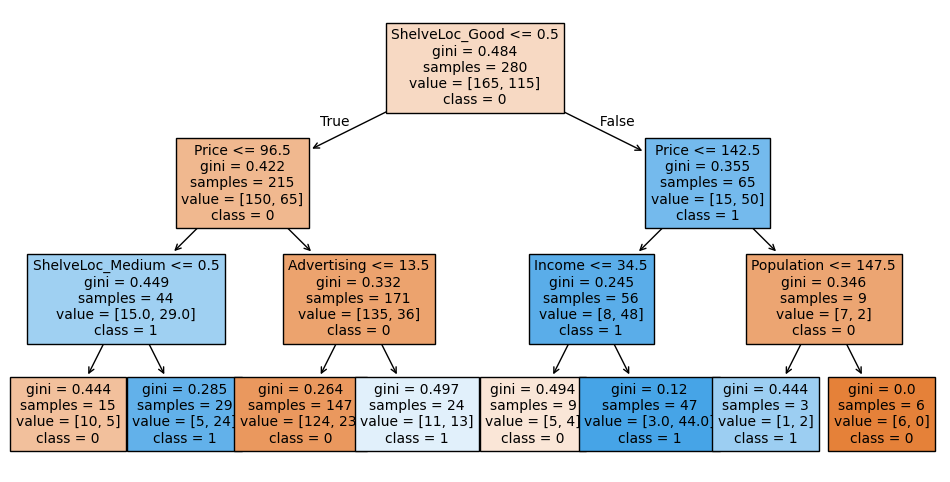

Train accuracy: 0.814
Test accuracy:  0.683


In [ ]:
plt.figure(figsize=(12, 6))

plot_tree(tree,
          feature_names=list(X.columns),
          class_names=['0', '1'], #here "Low" is first, because we set it up to be 0. class_names only changes the labels displayed on the tree. It does not change the model's predictions.
          filled=True, #colors nodes based on their predicted class. Stronger colors indicates greater purity
          fontsize=10)
plt.show()

print('Train accuracy:', round(tree.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree.score(X_test, y_test), 3))

## Part 2: Investigate Overfitting
1. Train decision trees with max_depth values from 1 to 10.
2. Use 5-fold cross-validation on the training data to calculate mean accuracy for each
depth.
3. Create a graph showing tree depth versus cross-validation accuracy.
4. Identify the best depth based on cross-validation.
5. Train a final tree using that depth and evaluate it on the test set.

In [ ]:
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=0),
    param_grid={'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]},
    cv=5)

grid.fit(X_train, y_train)

print('Best settings:', grid.best_params_)
print('Best CV accuracy:', round(grid.best_score_, 3))

Best settings: {'max_depth': 7}
Best CV accuracy: 0.779


3. Create a graph showing tree depth versus cross-validation accuracy.


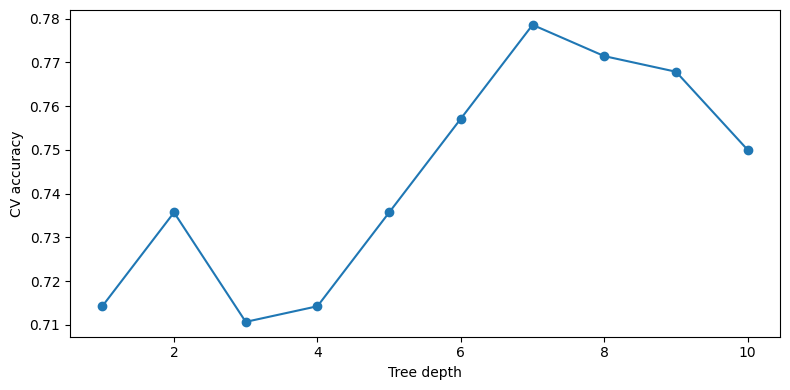

In [ ]:
depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
cv_acc = []


#2-Measure tree complexity (how many leaves)
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    cv_acc.append(cross_val_score(m, X_train, y_train, cv=5).mean())

#graph
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, cv_acc, marker='o'); ax.set_xlabel('Tree depth'); ax.set_ylabel('CV accuracy')
plt.tight_layout(); plt.show()

#best depth
best_depth = depths[int(np.argmax(cv_acc))]

4. Identify the best depth based on cross-validation.

    The best depth was 7, with the highest CV accuracy of 0.779 and a test accuracy of 0.717

5. Train a final tree using that depth and evaluate it on the test set.




In [ ]:
best_depth = DecisionTreeClassifier(max_depth = 7, random_state=0).fit(X_train, y_train)
print('Depth:', 7)
print('Train accuracy:', round(best_depth.score(X_train, y_train), 3))
print('Test accuracy: ', round(best_depth.score(X_test, y_test), 3))

Depth: 7
Train accuracy: 0.968
Test accuracy:  0.717


## Part 3: Answer the Following Questions
**1. Interpreting the tree: Which predictor was selected for the first split (root)? What does this split tell us about sales?**

  The first predictor selected for a split was ShelvLoc_Good, which I assume means a good shelving location for the product. This predictor did decrease the overall gini score for that leaf, which is good. It wasn't a dramatic drop but it did lower it overall.

**2. Choosing tree depth: According to your cross-validation graph, which depth performed best? Why should we use cross-validation rather than test accuracy to choose the depth?**

  A depth of 7 performed best, according to the cross validation graph. We should use cross validation because descicion trees are very unstable and even a slight variation in the data can alter results. Performing cross validation with the training data ensures that any variance in the training data is accounted for, and than we can grow the model to the best depth without using too much computing power. Using test accuracy to choose the depth would cause data leakage, for one thing. You can't use the testing data to choose a depth because then the model will be able to train with the testing data, leading to leakage.

**3. Overfitting: Does increasing tree depth always improve cross-validation accuracy? Explain using your graph.**

  No, in fact a full grown tree (the maximum tree depth) is rarely better for the model. A fully grown tree is overfitted to the training data because it keeps splitting and splitting until all the leaves are pure. It creates a model that is perfect for the training data and only for the training data. This leads to a higher test error than if the tree were limited in its depth and could better apply to a different set of data. As you look at the graph you can see that as the depth increases, after a certain point, the testing accuracy decreases. Thus, there is a sweet spot when it comes to depth, allowing the model to fit the training well enough that it can perform accurately on the testing data.